# 05 · Síntese e Recomendações para Investidores
**Tech Challenge – Fase 1 · POSTECH Data Analytics** · Trilha: *Crescimento e Receita*

Este notebook consolida os achados dos notebooks 02–04 em um painel de KPIs e estima, com premissas
explícitas e conservadoras, o potencial de receita das alavancas recomendadas.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from olist_utils import *

set_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

In [2]:
items = analysis_base()
ped = orders_base(items)
m = monthly_kpis(items)
R = items["price"].sum()
run_rate_mensal = m.loc["2018", "receita"].mean()
run_rate_anual = run_rate_mensal * 12
ticket = m["receita"].sum() / m["pedidos"].sum()

kpis = pd.Series({
    "Receita total jan/17–ago/18": brl(R),
    "Crescimento jan–ago/18 vs jan–ago/17": "+" + pct(m.loc["2018-01":"2018-08", "receita"].sum() / m.loc["2017-01":"2017-08", "receita"].sum() - 1),
    "Receita média mensal 2018 (run-rate)": brl(run_rate_mensal),
    "Receita anualizada 2018": brl(run_rate_anual),
    "Ticket médio": brl(ticket, 2),
    "Clientes únicos": fmt_int(ped["customer_unique_id"].nunique()),
    "Clientes com recompra": pct((ped.groupby("customer_unique_id")["order_id"].nunique() > 1).mean()),
    "Categorias que fazem 80% da receita": "18 de 74",
    "Receita do Sudeste": pct(items.loc[items["customer_region"] == "Sudeste", "price"].sum() / R),
    "Receita dos 10% maiores sellers": "67%",
})
kpis.to_frame("KPI")

,KPI
Receita total jan/17–ago/18,R$ 13.449.530
Crescimento jan–ago/18 vs jan–ago/17,"+138,3%"
Receita média mensal 2018 (run-rate),R$ 917.630
Receita anualizada 2018,R$ 11.011.556
Ticket médio,"R$ 137,37"
Clientes únicos,94.703
Clientes com recompra,"3,0%"
Categorias que fazem 80% da receita,18 de 74
Receita do Sudeste,"65,4%"
Receita dos 10% maiores sellers,67%


## Potencial das alavancas (dimensionamento ilustrativo)

Premissas conservadoras, ancoradas nos próprios dados – servem para **ordenar prioridades**, não como
meta financeira:

| Alavanca | Premissa | Base de cálculo |
|---|---|---|
| **1. Retenção / recompra** | recompra sobe de 3% para 8% dos clientes | clientes novos/ano (ritmo 2018) × 5 p.p. × ticket médio |
| **2. Norte/Nordeste** | receita por habitante dessas regiões +30% (frete regional, sellers locais) | receita anualizada N+NE em 2018 × 30% |
| **3. Categorias motor** | as 5 categorias que mais cresceram ganham +10% com mais investimento em mídia/sortimento | receita anualizada dessas categorias × 10% |
| **4. Black Friday e datas sazonais** | +20% sobre o pico de novembro já esperado | (efeito BF observado − 1) × run-rate × 20% |
| **5. Qualidade de sellers** | evitar perda de 25% da receita dos "grandes em risco" | 7% da receita × 25%, anualizado |

In [3]:
meses18 = 8  # jan–ago/2018
r18 = items[items["month"] >= "2018-01-01"]
clientes_novos_ano = (ped.assign(first=ped.groupby("customer_unique_id")["purchase"].transform("min"))
                        .query("purchase == first and month >= '2018-01-01'")["customer_unique_id"].nunique() / meses18 * 12)
nne_anual = r18[r18["customer_region"].isin(["Nordeste", "Norte"])]["price"].sum() / meses18 * 12
motor = ["beleza_saude", "relogios_presentes", "utilidades_domesticas", "bebes", "telefonia"]
motor_anual = r18[r18["product_category_name"].isin(motor)]["price"].sum() / meses18 * 12
efeito_bf = m.loc["2017-11-01", "receita"] / m.loc["2017-09":"2017-10", "receita"].mean()

alav = pd.Series({
    "Retenção / recompra": clientes_novos_ano * 0.05 * ticket,
    "Norte / Nordeste": nne_anual * 0.30,
    "Categorias motor": motor_anual * 0.10,
    "Black Friday / sazonais": (efeito_bf - 1) * run_rate_mensal * 0.20,
    "Proteção de sellers em risco": 0.07 * run_rate_anual * 0.25,
}).sort_values(ascending=False)
tab = alav.to_frame("receita adicional/ano")
tab["% do run-rate"] = (alav / run_rate_anual).map(pct)
tab["receita adicional/ano"] = tab["receita adicional/ano"].map(brl)
print(f"Run-rate anual 2018: {brl(run_rate_anual)} | potencial somado: {brl(alav.sum())} "
      f"(+{pct(alav.sum()/run_rate_anual)})")
tab

Run-rate anual 2018: R$ 11.011.556 | potencial somado: R$ 1.611.923 (+14,6%)


,receita adicional/ano,% do run-rate
Retenção / recompra,R$ 532.387,"4,8%"
Norte / Nordeste,R$ 436.077,"4,0%"
Categorias motor,R$ 346.775,"3,1%"
Proteção de sellers em risco,R$ 192.702,"1,8%"
Black Friday / sazonais,R$ 103.982,"0,9%"


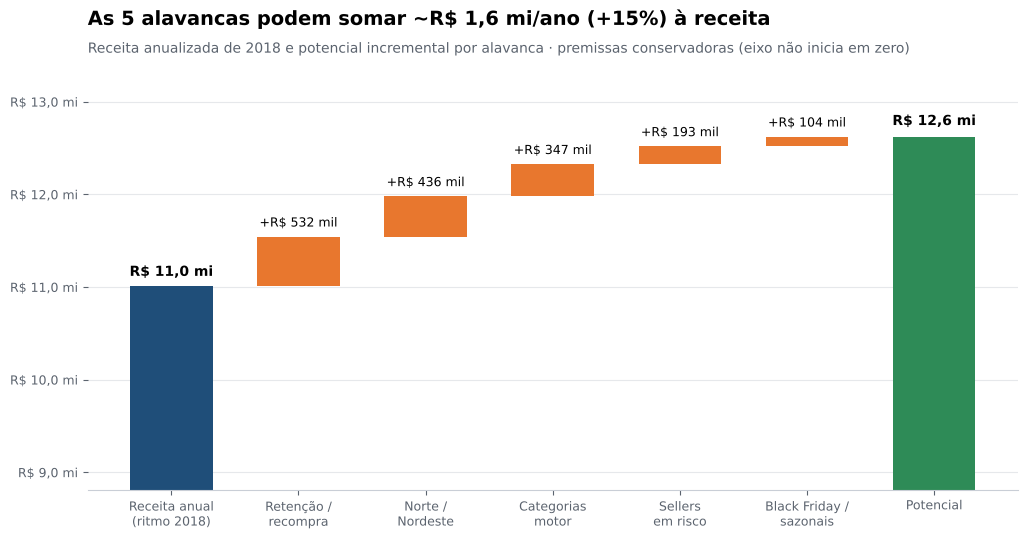

In [4]:
fig, ax = plt.subplots(figsize=(12, 5.5))
curto = {"Retenção / recompra": "Retenção /\nrecompra", "Norte / Nordeste": "Norte /\nNordeste",
         "Categorias motor": "Categorias\nmotor", "Proteção de sellers em risco": "Sellers\nem risco",
         "Black Friday / sazonais": "Black Friday /\nsazonais"}
labels = ["Receita anual\n(ritmo 2018)"] + [curto[l] for l in alav.index] + ["Potencial"]
vals = [run_rate_anual] + list(alav.values) + [run_rate_anual + alav.sum()]
bottom = 0
for i, v in enumerate(vals):
    if i == 0 or i == len(vals) - 1:
        ax.bar(i, v, color=COLORS["primary"] if i == 0 else COLORS["good"], width=0.65)
        ax.text(i, v * 1.01, brl_short(v), ha="center", fontsize=10, weight="bold")
        bottom = v
    else:
        ax.bar(i, v, bottom=bottom, color=COLORS["accent"], width=0.65)
        ax.text(i, bottom + v + run_rate_anual * 0.01, "+" + brl_short(v), ha="center", fontsize=9)
        bottom += v
ax.set_xticks(range(len(vals)), labels, fontsize=9)
ax.set_ylim(run_rate_anual * 0.8, (run_rate_anual + alav.sum()) * 1.06)
axis_brl(ax)
ax.set_title(f"As 5 alavancas podem somar ~{brl_short(alav.sum())}/ano (+{alav.sum()/run_rate_anual:.0%}) à receita")
subtitle(ax, "Receita anualizada de 2018 e potencial incremental por alavanca · premissas conservadoras (eixo não inicia em zero)")
save(fig, "15_alavancas_potencial")
plt.show()

## Recomendações (ordem de prioridade)

| # | Recomendação | Por quê (evidência) | KPI de acompanhamento |
|---|---|---|---|
| 1 | **Programa de recompra**: CRM pós-compra, cupom de 2ª compra, recomendações por categoria | 97% da receita vem de clientes novos; recompra de 3% | % clientes com 2+ pedidos em 90 dias |
| 2 | **Expansão Norte/Nordeste**: recrutar sellers locais, negociar frete regional, frete subsidiado acima de um valor mínimo | NE = 27% da população e 11% da receita; frete 20–28% do valor do produto | receita por mil hab. no NE; frete/receita |
| 3 | **Investir nas categorias motor** (beleza & saúde, relógios, utilidades, bebês, telefonia) e revisar as travadas (cool stuff, brinquedos, perfumaria) | crescem 2–3x a média; travadas abaixo de 50% | crescimento por categoria vs média |
| 4 | **Gestão de sellers**: contas-chave para o top 10%; plano de melhoria para "grandes em risco"; vitrine para "estrelas" e "promessas" | top 10% = 67% da receita; 28 grandes sellers com nota < 3,8 ou atraso > 15% | nota média e % atraso do top 10% |
| 5 | **Calendário sazonal**: preparar estoque, frete e mídia para Black Friday/Natal | Black Friday = 1,6x o mês e 6x um dia normal | receita de novembro vs previsão |

## Mensagem para investidores
A Olist provou tração (+138% no ano), mas **entrou em platô em 2018** (~R$ 0,9 mi/mês na amostra).
O crescimento foi 100% via novos clientes, com recompra quase nula, concentração geográfica e de sellers.
As alavancas identificadas são **operacionais e de baixo risco** – retenção, expansão regional e gestão de
sellers – e podem adicionar ~15% (≈ R$ 1,6 mi) à receita anual. O investimento deve ser condicionado a metas claras de
**recompra** e **penetração regional**.